In [1]:
# General imports 
import os 
import re
import numpy as np
import pandas as pd
from pathlib import Path
import scipy.stats as stats 
from skimage import measure
import matplotlib.pyplot as plt
import math

# Pynwb imports
from hdmf_zarr import NWBZarrIO
from nwbwidgets import nwb2widget

import sys
# Add the directory that contains the 'bci' folder
sys.path.insert(0, '/code/src/')  # Note: changed to /code/src/ not /code/src/bci/

# Now these imports should work
from bci.loaders import load
from bci.loaders import results
from bci.processing import processing

In [2]:
def correlation_prepost_bci(dff_traces, photostim_pre_start, photostim_pre_stop, 
                           photostim_post_start, photostim_post_stop, valid_roi_table):
    #import numpy as np
    #import matplotlib.pyplot as plt
    #from scipy import stats
    
    # Index into the dff traces array to limit to the relevant time points
    dff_pre = dff_traces[photostim_pre_start:photostim_pre_stop, :]
    dff_pre = dff_pre.T
    dff_post = dff_traces[photostim_post_start:photostim_post_stop, :]
    dff_post = dff_post.T
                            
    # Limit dff traces for photostimulation activity period before the task to valid ROIs
    dff_pre = dff_pre[valid_roi_table.index.values, :]
    print(f"dff_pre shape: {dff_pre.shape}")
    
    # Limit dff traces for photostimulation activity period after the task to valid ROIs
    dff_post = dff_post[valid_roi_table.index.values, :]
    print(f"dff_post shape: {dff_post.shape}")
    
    # Calculate correlation matrices
    correlations_pre = np.corrcoef(dff_pre)
    correlations_post = np.corrcoef(dff_post)
    
    # Keep only upper triangular part (avoid duplicate pairs and diagonal)
    correlations_pre = np.triu(correlations_pre, k=1)
    correlations_post = np.triu(correlations_post, k=1)
    
    # Statistical comparison
    t, p_val = stats.ttest_ind(correlations_pre.flatten(), correlations_post.flatten())
    print(f"T-test p-value: {p_val}")
    
    # Plot both distributions
    plt.figure(figsize=(10, 6))
    plt.hist(correlations_pre.flatten(), bins=100, color='green', label='pre', histtype='step')
    plt.hist(correlations_post.flatten(), bins=100, color='purple', label='post', histtype='step')
    plt.title('Correlations before and after BCI learning, p=' + str(np.round(p_val, 5)))
    plt.xlabel('Correlation')
    plt.ylabel('# cell pairs')
    plt.xlim(-0.1, 0.1)
    plt.legend()
    plt.show()
    
    return correlations_pre, correlations_post, p_val

def photostim_prepost_frames(epoch_table):
    epoch_table['duration'] = epoch_table.stop_time - epoch_table.start_time
    
    # Define the stimulus names we're looking for
    photostim = ['photostim', 'photostim_post']
    relevant_epochs = epoch_table[epoch_table['stimulus_name'].isin(photostim)].copy()
    relevant_epochs['duration'] = relevant_epochs.stop_time - relevant_epochs.start_time
    
    # Set stimulus_name as index for direct access
    indexed_epochs = relevant_epochs.set_index('stimulus_name')
    
    # Now you can directly access by stimulus name and convert to integers
    photostim_pre_start = int(indexed_epochs.loc['photostim'].start_frame)
    photostim_pre_stop = int(indexed_epochs.loc['photostim'].stop_frame)
    photostim_post_start = int(indexed_epochs.loc['photostim_post'].start_frame)
    photostim_post_stop = int(indexed_epochs.loc['photostim_post'].stop_frame)
    
    return photostim_pre_start, photostim_pre_stop, photostim_post_start, photostim_post_stop

In [3]:
metadata = load.load_filtered_metadata()
# Select a specific subject
target_subject_id = 754303
i_sess=5
# Filter metadata for that subject
subject_sessions754303  = metadata[metadata['subject_id'] == target_subject_id]
sesh_zero = subject_sessions754303['name'].values[i_sess]
date = subject_sessions754303['session_date'].values[i_sess]
full_session_data = load.load_session_data(sesh_zero)

BCI data directory: /data/brain-computer-interface

Session directory: /data/brain-computer-interface/single-plane-ophys_754303_2025-02-03_15-24-22_processed_2025-08-04_04-23-48

NWB file: single-plane-ophys_754303_2025-02-03_15-24-22_behavior_nwb
NWB path: /data/brain-computer-interface/single-plane-ophys_754303_2025-02-03_15-24-22_processed_2025-08-04_04-23-48/single-plane-ophys_754303_2025-02-03_15-24-22_behavior_nwb


/opt/conda/lib/python3.10/site-packages/hdmf/spec/namespace.py:535: UserWarning: Ignoring cached namespace 'core' version 2.7.0 because version 2.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."


All threshold files for mouse 754303: ['single-plane-ophys_754303_2025-01-27', 'single-plane-ophys_754303_2025-01-23', 'single-plane-ophys_754303_2025-01-29', 'single-plane-ophys_754303_2025-01-31', 'single-plane-ophys_754303_2025-02-03']

Found threshold file at: /data/bci-thresholds/single-plane-ophys_754303_2025-02-03
total difference in dataframes: 24


In [4]:
sesh_zero

'single-plane-ophys_754303_2025-02-03_15-24-22_processed_2025-08-04_04-23-48'

In [5]:
subject_sessions754303

,project_name,session_type,_id,name,subject_id,genotype,virus,date_of_birth,sex,modality,session_date,age,session_time,targeted_structure,ophys_fov,session_number
14,Brain Computer Interface,BCI single neuron stim,3aac9323-c4f9-4172-9f1a-6c12cb3bc44e,single-plane-ophys_754303_2025-01-22_18-22-38_...,754303,Camk2a-tTA/wt;TetO-jGCaMP8s-01/wt,pAAV-CaMKIIa-ChRmine-oScarlet-Kv2.1-WPRE - 7413,2024-07-17,Male,Planar optical physiology,2025-01-22,189,16:59:35.618000,Primary Motor Cortex,FOV_01,2.0
15,Brain Computer Interface,BCI single neuron stim,7efb85e4-0dba-43fe-a0fd-2b8348e05b69,single-plane-ophys_754303_2025-01-27_20-01-31_...,754303,Camk2a-tTA/wt;TetO-jGCaMP8s-01/wt,pAAV-CaMKIIa-ChRmine-oScarlet-Kv2.1-WPRE - 7413,2024-07-17,Male,Planar optical physiology,2025-01-27,194,18:46:54.109999,Primary Motor Cortex,FOV_01,5.0
16,Brain Computer Interface,BCI single neuron stim,aaf560f4-bb1f-449a-aaf9-5054432b47ae,single-plane-ophys_754303_2025-01-23_19-48-32_...,754303,Camk2a-tTA/wt;TetO-jGCaMP8s-01/wt,pAAV-CaMKIIa-ChRmine-oScarlet-Kv2.1-WPRE - 7413,2024-07-17,Male,Planar optical physiology,2025-01-23,190,18:36:30.521000,Primary Motor Cortex,FOV_01,3.0
17,Brain Computer Interface,BCI single neuron stim,5fa54429-8887-48b7-a3db-5526d7fa3fe5,single-plane-ophys_754303_2025-01-29_16-07-41_...,754303,Camk2a-tTA/wt;TetO-jGCaMP8s-01/wt,pAAV-CaMKIIa-ChRmine-oScarlet-Kv2.1-WPRE - 7413,2024-07-17,Male,Planar optical physiology,2025-01-29,196,16:07:41.655000,Primary Motor Cortex,FOV_01,6.0
18,Brain Computer Interface,BCI single neuron stim,737557e6-4bb3-423f-8fae-a2a63ee600e7,single-plane-ophys_754303_2025-01-31_15-13-50_...,754303,Camk2a-tTA/wt;TetO-jGCaMP8s-01/wt,pAAV-CaMKIIa-ChRmine-oScarlet-Kv2.1-WPRE - 7413,2024-07-17,Male,Planar optical physiology,2025-01-31,198,15:13:50.595999,Primary Motor Cortex,FOV_01,8.0
19,Brain Computer Interface,BCI single neuron stim,02859cbf-4099-4508-a2d1-6bad82ffcebb,single-plane-ophys_754303_2025-02-03_15-24-22_...,754303,Camk2a-tTA/wt;TetO-jGCaMP8s-01/wt,pAAV-CaMKIIa-ChRmine-oScarlet-Kv2.1-WPRE - 7413,2024-07-17,Male,Planar optical physiology,2025-02-03,201,15:24:22.163000,Primary Motor Cortex,FOV_02,9.0


In [6]:
dff_traces = full_session_data['dff_traces']

In [7]:
epoch_table = full_session_data['epoch_table']

In [8]:
[photostim_pre_start, photostim_pre_stop, photostim_post_start, photostim_post_stop] = photostim_prepost_frames(epoch_table)

In [9]:
# Select valid ROI
valid_rois, cn_index = processing.filter_somas(full_session_data)

CN: [5]


dff_pre shape: (124, 60698)
dff_post shape: (124, 72750)
T-test p-value: 0.014959469078766705


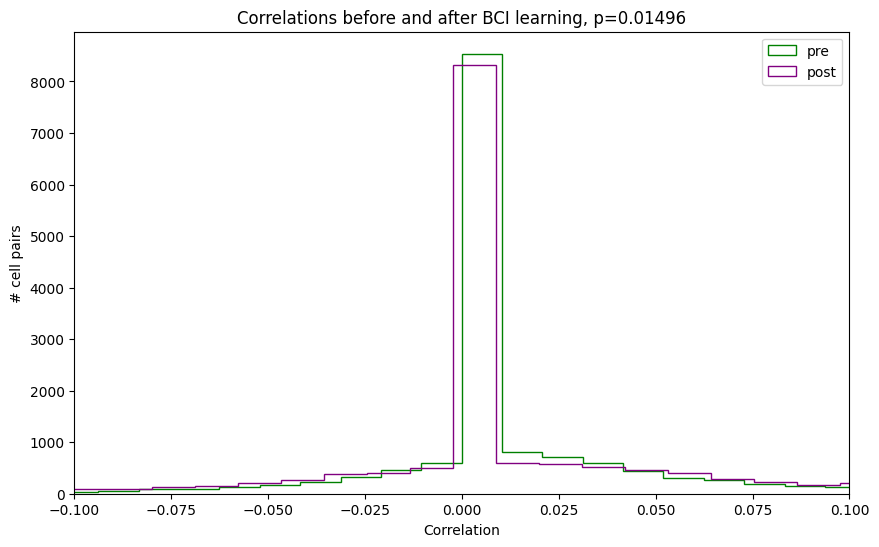

In [10]:
[correlations_pre, correlations_post, p_val] = correlation_prepost_bci(dff_traces, photostim_pre_start, photostim_pre_stop, photostim_post_start, photostim_post_stop, valid_rois)

In [11]:
res = results.Results.from_python_hdf5(f'/data/camila_results_bci_workshop/754303/{sesh_zero}/svm_sample/svm_results.h5')
print(res.__dict__.keys())
#res.score_test

dict_keys(['pipeline', 'comment', '_Results__created', 'dff_by_trial_st_end', 'rois_idx', 'score_test', 'score_train', 'svc_coeff'])


In [12]:
res.svc_coeff.shape

(100, 3, 124)

In [13]:
weights = np.mean(res.svc_coeff, axis = 0)

In [14]:
weights.shape

(3, 124)

In [15]:
early = weights[0]
late = weights[2]

(np.float64(0.0), np.float64(124.0), np.float64(0.0), np.float64(124.0))

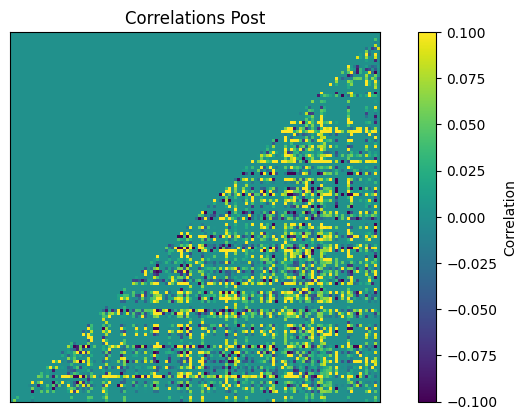

In [16]:
idx_late = np.argsort(np.abs(late))
idx_late.shape
res.rois_idx[idx_late]

np.sum(valid_rois.index.values == res.rois_idx)

second_sort = correlations_post[idx_late]
second_sort = second_sort[:, idx_late]
second_sort

# Keep only upper triangular part (avoid duplicate pairs and diagonal)
second_sort = np.triu(second_sort, k=1)
#correlations_post = np.triu(correlations_post, k=1)

plt.pcolormesh(second_sort, cmap='viridis', vmin=-0.1, vmax=0.1)
plt.colorbar(label='Correlation')
#plt.xlabel('')
#plt.ylabel('ROI ID')
plt.title('Correlations Post')
plt.xticks([]) # Remove x-axis ticks and labels
plt.yticks([]) # Remove y-axis ticks and labels
plt.axis('square')
#plt.savefig('/code/scripts/miguel/Graphs/M754303-S3:Corr_post.png', dpi=300, bbox_inches='tight')

(np.float64(0.0), np.float64(124.0), np.float64(0.0), np.float64(124.0))

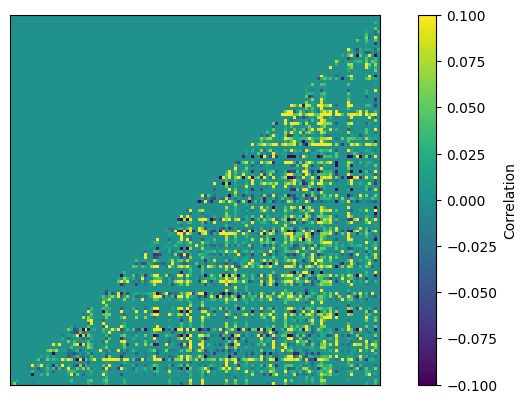

In [17]:
#idx_early = np.argsort(np.abs(early))
#idx_early.shape
#res.rois_idx[idx_late]

np.sum(valid_rois.index.values == res.rois_idx)

first_sort = correlations_pre[idx_late]
first_sort = first_sort[:, idx_late]
first_sort

# Keep only upper triangular part (avoid duplicate pairs and diagonal)
first_sort = np.triu(first_sort, k=1)
#correlations_post = np.triu(correlations_post, k=1)

plt.pcolormesh(first_sort, cmap='viridis', vmin=-0.1, vmax=0.1)
plt.colorbar(label='Correlation')
plt.xlabel('')
#plt.ylabel('ROI ID')
#plt.title('Correlations Pre')
plt.xticks([]) # Remove x-axis ticks and labels
plt.yticks([]) # Remove y-axis ticks and labels
plt.axis('square')
#plt.savefig('/code/scripts/miguel/Graphs/M754303-S3:Corr_post.png', dpi=300, bbox_inches='tight')

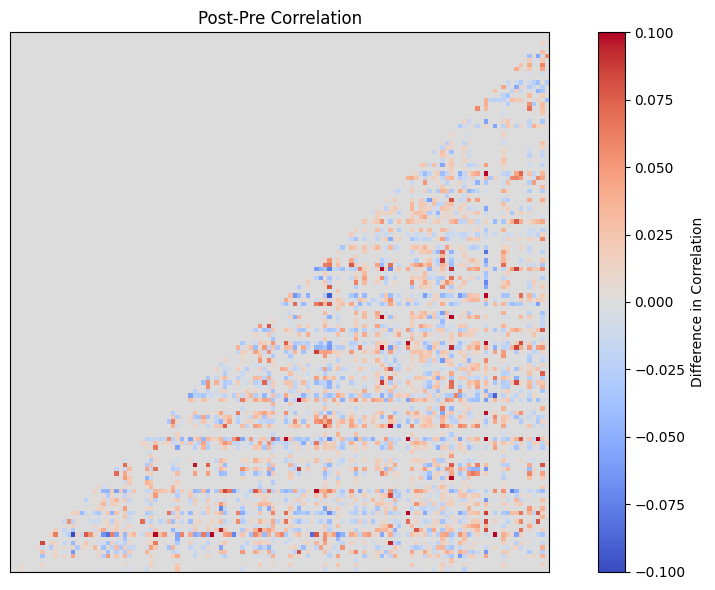

In [18]:
fig, (ax2) = plt.subplots(figsize=(10, 6))



# Post-learning correlations  
im2 = ax2.pcolormesh(second_sort-first_sort, cmap='coolwarm', vmin=-0.1, vmax=0.1)
ax2.set_title('Post-Pre Correlation')
ax2.set_xticks([])
ax2.set_yticks([])
ax2.set_aspect('equal')

# Add colorbar

# Add colorbar only to the right plot
plt.tight_layout()
cbar = plt.colorbar(im2, ax=ax2)
cbar.set_label('Difference in Correlation')
plt.tight_layout()
plt.savefig(f'/code/scripts/miguel/Graphs/M754303-{date}:Corr_both.png', dpi=300, bbox_inches='tight')
plt.show()